# Machine Learning Theory: Kernel Methods

> **Who is this for:** you have used `SVC(kernel="rbf")` ([`05_svm`](../01_supervised/05_svm.ipynb)) and want to understand what a kernel *is*, why it works, and how kernel methods are built, scaled and applied beyond SVMs. This is standard MS-level "Advanced ML" material, and kernels remain the cleanest way to understand very wide neural networks.
>
> **What you will learn:**
> - **Feature maps vs kernels**: computing inner products in a huge feature space without ever building it
> - **Mercer's condition**: a function is a valid kernel exactly when every Gram matrix is positive semidefinite (PSD); checking this numerically, and the rules for building new kernels from old ones
> - The **RKHS** (reproducing kernel Hilbert space) in plain words, and the **representer theorem**, demonstrated numerically
> - **Kernel ridge regression** from scratch, compared with scikit-learn, with a bandwidth × regularisation grid
> - **Kernel PCA** and **kernel k-means** from scratch on data that linear methods cannot handle
> - The $O(n^3)$ scalability problem and two fixes from scratch: the **Nyström** method and **random Fourier features**, with approximation-error curves and timings
> - The kernel two-sample test (**MMD**) for data-drift detection
> - The **kernel–Gaussian-process connection**: the same posterior mean, verified numerically
> - Kernels for **strings** (spectrum kernel) and **graphs** (Weisfeiler–Lehman)
> - The **neural tangent kernel**: a very wide network trained by gradient descent behaves like kernel regression
>
> **Prerequisites:** [`01_statistical_learning_theory`](01_statistical_learning_theory.ipynb) (capacity, margins, norms); [linear algebra](../../14_Mathematics/01_linear_algebra.ipynb) (eigenvalues, PSD matrices); [SVMs](../01_supervised/05_svm.ipynb); [dimensionality reduction](../02_unsupervised/02_dimensionality_reduction.ipynb) (PCA). The SVM dual, where kernels first appear, is derived in [`14_Mathematics/12_convex_optimization_and_duality`](../../14_Mathematics/12_convex_optimization_and_duality.ipynb).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about 1–2 minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Schölkopf & Smola, *Learning with Kernels* (2002), Shawe-Taylor & Cristianini, *Kernel Methods for Pattern Analysis* (2004), and Rasmussen & Williams, *Gaussian Processes for Machine Learning* (2006).

## Explained simply

Many patterns are not straight lines. Points inside a circle and points outside it cannot be separated by any straight cut. A classic trick is to add new **features**: if you add "distance from the centre" as a third coordinate, the inside points sit low and the outside points sit high, and now a flat cut separates them. A **kernel** is a shortcut that lets an algorithm use enormous numbers of such extra features, even infinitely many, without ever computing them. It only needs one number for each pair of examples: **how similar are these two?**

Two everyday pictures:
- **A music app recommending songs** does not need a list of every property of every song. It is enough to know "how similar is song A to song B", and a kernel is exactly such a similarity score.
- **Comparing two handwriting samples** by overlaying them and measuring how much they overlap is a similarity that implicitly compares thousands of pixel features at once.

**Tiny example.** Take two points $x = (1, 2)$ and $z = (3, 1)$. Their dot product is $1 \cdot 3 + 2 \cdot 1 = 5$. The kernel $k(x, z) = (x \cdot z + 1)^2 = 6^2 = 36$. That *same* number 36 is the dot product of two 6-number feature vectors $(x_1^2, x_2^2, \sqrt2 x_1x_2, \sqrt2 x_1, \sqrt2 x_2, 1)$. For $x$: $(1, 4, 2.83, 1.41, 2.83, 1)$; for $z$: $(9, 1, 4.24, 4.24, 1.41, 1)$. Multiply them coordinate by coordinate and add: $9 + 4 + 12 + 6 + 4 + 1 = 36$. The kernel got the answer with one multiplication, one addition and one square, without building the longer vectors.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Kernel | a similarity score that secretly equals a dot product of (many) features | RBF-SVMs, Gaussian processes, attention scores in transformers |
| Representer theorem | the best model is a weighted sum of similarities to the training examples | why SVMs and GPs only need the training points |
| Random features / Nyström | cheap approximations that make kernels work on big data | large-scale kernel models, linear-attention transformers |

### How this notebook is different from existing notebooks
- [`05_svm`](../01_supervised/05_svm.ipynb) introduces the kernel trick for SVMs and uses `SVC(kernel=...)`.
- Gaussian processes appear in [`04_uncommon_models`](../04_uncommon_models/01_uncommon_ml_models.ipynb) and [`14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb).

This notebook is the **theory and toolbox** behind all of them. It covers what makes a valid kernel, why solutions take the form $\sum_i \alpha_i k(x_i, \cdot)$, and how to implement, scale and test kernel methods yourself.

## Table of contents
1. Feature maps vs kernels; Mercer's condition; building kernels
2. RKHS intuition and the representer theorem
3. Kernel ridge regression from scratch
4. Kernel PCA and kernel k-means
5. Scaling up: Nyström and random Fourier features
6. The kernel two-sample test (MMD) for drift detection
7. The kernel–Gaussian-process connection
8. Kernels for structured data: strings and graphs
9. The neural tangent kernel
10. Summary table
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from scipy import stats
from sklearn.kernel_ridge import KernelRidge
from sklearn.decomposition import KernelPCA, PCA
from sklearn.cluster import KMeans
from sklearn.datasets import make_circles
from sklearn.metrics import adjusted_rand_score
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from collections import Counter
import itertools, warnings
import networkx as nx
rng = np.random.default_rng(0)

def sqdist(A, B):
    """Matrix of squared Euclidean distances between rows of A and rows of B."""
    return np.maximum((A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T, 0)

def rbf_kernel(A, B, gamma):
    """Gaussian / RBF kernel k(x, z) = exp(-gamma ||x - z||^2)."""
    return np.exp(-gamma * sqdist(A, B))

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. Feature maps vs kernels; Mercer's condition; building kernels

> 💬 **In plain English:** a kernel is a similarity score that secretly equals a dot product of feature vectors, and only some similarity scores qualify.

A **feature map** $\phi: \mathcal X \to \mathcal F$ sends each input to a (possibly huge) feature vector. A **kernel** is a function $k(x, z) = \langle \phi(x), \phi(z)\rangle$ that returns the inner product of the feature vectors directly. Any algorithm that touches the data **only through inner products** (SVM dual, ridge regression, PCA, k-means, distances) can be "kernelised" by replacing $x^\top z$ with $k(x, z)$: the **kernel trick**.

| Kernel | Formula | Feature space |
|---|---|---|
| linear | $x^\top z$ | the inputs themselves |
| polynomial | $(x^\top z + c)^p$ | all monomials up to degree $p$: $\binom{d+p}{p}$ dimensions |
| RBF / Gaussian | $\exp(-\gamma\lVert x - z\rVert^2)$ | infinite-dimensional |
| Laplacian | $\exp(-\gamma\lVert x - z\rVert_1)$ | infinite-dimensional, less smooth |

The **Gram matrix** of points $x_1, \dots, x_n$ is $K_{ij} = k(x_i, x_j)$.

**Mercer / Moore–Aronszajn:** a symmetric function $k$ is a valid kernel (it equals $\langle\phi(x), \phi(z)\rangle$ for *some* feature map) **if and only if** every Gram matrix it produces is **positive semidefinite**: $c^\top K c \ge 0$ for all $c$. Such kernels are called *positive definite kernels*. A single Gram matrix with a negative eigenvalue proves a function is *not* a kernel.

First we verify the hand example from the *Explained simply* section, then check that the RBF kernel really is an infinite sum of feature products.

In [2]:
def phi_poly2(x):
    """Explicit feature map of k(x, z) = (x.z + 1)^2 for 2-D inputs (6 features)."""
    x1, x2 = x
    s = np.sqrt(2)
    return np.array([x1**2, x2**2, s * x1 * x2, s * x1, s * x2, 1.0])

x, z = np.array([1.0, 2.0]), np.array([3.0, 1.0])
print("phi(x) =", phi_poly2(x).round(2), "\nphi(z) =", phi_poly2(z).round(2))
print("phi(x).phi(z) =", phi_poly2(x) @ phi_poly2(z), "   kernel (x.z + 1)^2 =", (x @ z + 1) ** 2)
P = rng.normal(size=(1000, 2)); Q = rng.normal(size=(1000, 2))
assert np.allclose([phi_poly2(p) @ phi_poly2(q) for p, q in zip(P, Q)], ((P * Q).sum(1) + 1) ** 2)

# RBF in 1-D: exp(-(x-z)^2/2) = sum_n phi_n(x) phi_n(z) with phi_n(x) = exp(-x^2/2) x^n / sqrt(n!)
from math import factorial
def phi_rbf_truncated(x, N):
    return np.array([np.exp(-x**2 / 2) * x**n / np.sqrt(factorial(n)) for n in range(N)])
for N in [1, 3, 5, 10, 20]:
    approx = phi_rbf_truncated(1.3, N) @ phi_rbf_truncated(-0.4, N)
    print(f"RBF with the first {N:2d} features: {approx:.6f}   exact exp(-(1.3+0.4)^2/2) = {np.exp(-(1.7)**2 / 2):.6f}")

phi(x) = [1.   4.   2.83 1.41 2.83 1.  ] 
phi(z) = [9.   1.   4.24 4.24 1.41 1.  ]
phi(x).phi(z) = 36.0    kernel (x.z + 1)^2 = 36.0
RBF with the first  1 features: 0.396531   exact exp(-(1.3+0.4)^2/2) = 0.235746
RBF with the first  3 features: 0.243946   exact exp(-(1.3+0.4)^2/2) = 0.235746
RBF with the first  5 features: 0.235862   exact exp(-(1.3+0.4)^2/2) = 0.235746
RBF with the first 10 features: 0.235746   exact exp(-(1.3+0.4)^2/2) = 0.235746
RBF with the first 20 features: 0.235746   exact exp(-(1.3+0.4)^2/2) = 0.235746


In [3]:
def min_gram_eig(kfun, X):
    """Smallest eigenvalue of the Gram matrix (>= -1e-9 means PSD up to rounding)."""
    K = kfun(X, X)
    return np.linalg.eigvalsh((K + K.T) / 2).min()

Xg = rng.normal(size=(100, 3))
Xpos = np.abs(Xg)                                         # some kernels need positive inputs
candidates = {
    "linear  x.z":                        (lambda A, B: A @ B.T, Xg),
    "polynomial (x.z + 1)^3":             (lambda A, B: (A @ B.T + 1) ** 3, Xg),
    "RBF exp(-0.5||x-z||^2)":             (lambda A, B: rbf_kernel(A, B, 0.5), Xg),
    "Laplacian exp(-||x-z||_1)":          (lambda A, B: np.exp(-np.abs(A[:, None] - B[None]).sum(-1)), Xg),
    "min(x, z) on x >= 0 (1-D)":          (lambda A, B: np.minimum(A[:, :1], B[:, :1].T), Xpos),
    "sigmoid tanh(2 x.z - 1)":            (lambda A, B: np.tanh(2 * A @ B.T - 1), Xg),
    "squared distance ||x-z||^2":         (lambda A, B: sqdist(A, B), Xg),
    "negative distance -||x-z||":         (lambda A, B: -np.sqrt(sqdist(A, B)), Xg),
}
rows = [{"function": name, "min Gram eigenvalue": min_gram_eig(k, X_), "valid kernel?": "yes" if min_gram_eig(k, X_) > -1e-8 else "NO"}
        for name, (k, X_) in candidates.items()]
pd.DataFrame(rows).round(6)

,function,min Gram eigenvalue,valid kernel?
0,linear x.z,-0.000000,yes
1,polynomial (x.z + 1)^3,-0.000000,yes
2,RBF exp(-0.5||x-z||^2),0.000001,yes
3,Laplacian exp(-||x-z||_1),0.137313,yes
4,"min(x, z) on x >= 0 (1-D)",0.000103,yes
5,sigmoid tanh(2 x.z - 1),-27.793993,NO
6,squared distance ||x-z||^2,-241.592489,NO
7,negative distance -||x-z||,-232.357217,NO


**What just happened?**
- The explicit 6-feature map reproduces $(x^\top z + 1)^2 = 36$, and agrees with the kernel on 1,000 random pairs.
- The truncated RBF features converge to the exact kernel value as more features are added. The RBF kernel really is an inner product in an infinite-dimensional space; we just never have to build it.
- The PSD check separates valid kernels (linear, polynomial, RBF, Laplacian, $\min(x, z)$, the covariance of Brownian motion) from invalid ones. The popular "sigmoid kernel" $\tanh(a\,x^\top z + c)$ is **not** PSD for these parameters, even though libraries offer it. A squared distance is a *dissimilarity*: its Gram matrix has zero diagonal and positive off-diagonal entries, so its eigenvalues must sum to 0 and some are negative. The negative distance $-\lVert x - z\rVert$ is only *conditionally* PSD (PSD on vectors with $\sum c_i = 0$), so it fails too.

### Building new kernels from old ones

If $k_1, k_2$ are kernels, so are: $a k_1$ ($a \ge 0$), $k_1 + k_2$, $k_1 \cdot k_2$, $f(x)k_1(x, z)f(z)$ for any function $f$, $p(k_1)$ for a polynomial $p$ with non-negative coefficients, $\exp(k_1)$, and $k_1(\psi(x), \psi(z))$ for any map $\psi$. These rules are how kernels for new data types are engineered. For example, the RBF kernel is $f(x)\exp(2\gamma x^\top z)f(z)$ with $f(x) = e^{-\gamma\lVert x\rVert^2}$. A **difference** of kernels is not guaranteed to be a kernel.

In [4]:
k1 = lambda A, B: rbf_kernel(A, B, 0.5)
k2 = lambda A, B: (A @ B.T + 1) ** 2
f = lambda A: np.cos(A[:, 0])[:, None]                      # any real function of x
built = {
    "3 * k1":              lambda A, B: 3 * k1(A, B),
    "k1 + k2":             lambda A, B: k1(A, B) + k2(A, B),
    "k1 * k2":             lambda A, B: k1(A, B) * k2(A, B),
    "f(x) k2(x,z) f(z)":   lambda A, B: f(A) * k2(A, B) * f(B).T,
    "exp(0.2 * k2)":       lambda A, B: np.exp(0.2 * k2(A, B)),
    "k1(x^3, z^3)":        lambda A, B: k1(A**3, B**3),
    "k1 - 0.5 * k2":       lambda A, B: k1(A, B) - 0.5 * k2(A, B),
}
Xs3 = rng.normal(size=(60, 3)) * 0.6
for name, k in built.items():
    K = k(Xs3, Xs3)
    lam_min = np.linalg.eigvalsh((K + K.T) / 2).min()
    print(f"{name:20s} min eigenvalue / max eigenvalue = {lam_min / np.abs(np.linalg.eigvalsh(K)).max():+.2e}")

3 * k1               min eigenvalue / max eigenvalue = +1.05e-08
k1 + k2              min eigenvalue / max eigenvalue = +2.86e-09
k1 * k2              min eigenvalue / max eigenvalue = +2.28e-07
f(x) k2(x,z) f(z)    min eigenvalue / max eigenvalue = -2.11e-16
exp(0.2 * k2)        min eigenvalue / max eigenvalue = +7.66e-09
k1(x^3, z^3)         min eigenvalue / max eigenvalue = +1.20e-15
k1 - 0.5 * k2        min eigenvalue / max eigenvalue = -1.00e+00


**What just happened?** Every construction allowed by the rules gives a Gram matrix whose smallest eigenvalue is non-negative up to rounding, relative to the largest one (tiny values like $-10^{-17}$ are floating-point noise). The difference $k_1 - 0.5k_2$ has a clearly negative eigenvalue, so it is not a kernel.

⚠️ **Common mistake:** "my similarity is symmetric and bigger for similar items, so it's a kernel." Symmetry is not enough; PSD is required. An invalid "kernel" can make the SVM dual non-convex and solvers fail or return nonsense.

## 2. RKHS intuition and the representer theorem

Every valid kernel comes with its own space of functions, and the best function in that space is always built from the training points alone.

**Reproducing kernel Hilbert space (RKHS).** Given a kernel $k$, take all functions of the form $f(\cdot) = \sum_i \alpha_i k(x_i, \cdot)$ (bumps centred at points) and their limits. Define the inner product by $\langle k(x, \cdot), k(z, \cdot)\rangle_{\mathcal H} = k(x, z)$. This space $\mathcal H_k$ is the RKHS, and it has two key properties:
- **Reproducing property:** $f(x) = \langle f, k(x, \cdot)\rangle_{\mathcal H}$. Evaluating a function is an inner product with a kernel bump.
- **Norm = complexity:** for $f = \sum_i \alpha_i k(x_i, \cdot)$, $\lVert f\rVert_{\mathcal H}^2 = \alpha^\top K \alpha$. For the RBF kernel, a small RKHS norm means a smooth function. Penalising $\lVert f \rVert_{\mathcal H}$ is the kernel version of weight decay, and the margin and Rademacher bounds of [`01_statistical_learning_theory`](01_statistical_learning_theory.ipynb) depend on it.

**Representer theorem** (Kimeldorf & Wahba, 1971; Schölkopf, Herbrich & Smola, 2001). For any loss $L$ and any strictly increasing function $\Omega$, every minimiser of

$$\sum_{i=1}^n L\big(y_i, f(x_i)\big) + \Omega\big(\lVert f\rVert_{\mathcal H}\big)$$

over the *whole* (possibly infinite-dimensional) RKHS has the form $f^\star = \sum_{i=1}^n \alpha_i k(x_i, \cdot)$.

**Proof idea:** split any $f$ into a part in $\operatorname{span}\{k(x_i, \cdot)\}$ and a part orthogonal to it. By the reproducing property the orthogonal part does not change any $f(x_i)$, so it cannot reduce the loss, but it adds to the norm. So the optimal orthogonal part is zero.

**Demonstration.** Fit kernel ridge regression (Section 3) on 30 training points, then refit allowing 30 *extra* bump centres at random non-training locations. If the theorem holds, the extra bumps cannot help, and the fitted function must be identical.

max |f_with_extra_centres - f_representer| on a fine grid = 6.67e-10
RKHS norm^2: representer form 2.088772, with extra centres 2.088772


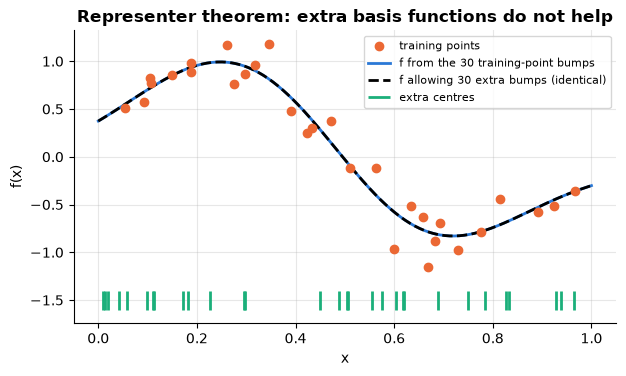

In [5]:
r2 = np.random.default_rng(2)
x_tr = np.sort(r2.random(30))[:, None]; y_tr = np.sin(2 * np.pi * x_tr[:, 0]) + 0.2 * r2.normal(size=30)
extra = r2.random(30)[:, None]                                     # centres that are NOT training points
g2, lam2 = 10.0, 0.1
x_plot = np.linspace(0, 1, 300)[:, None]

# (a) representer form: f = sum over training points;  alpha = (K + lam I)^-1 y
alpha2 = np.linalg.solve(rbf_kernel(x_tr, x_tr, g2) + lam2 * np.eye(30), y_tr)
f_a = rbf_kernel(x_plot, x_tr, g2) @ alpha2

# (b) a bigger model: f = sum over training points AND extra centres, same objective
#     min ||y - A beta||^2 + lam * beta^T G beta,  A = K(train, centres), G = K(centres, centres)
centres = np.vstack([x_tr, extra])
A2, G2 = rbf_kernel(x_tr, centres, g2), rbf_kernel(centres, centres, g2)
beta2 = np.linalg.lstsq(A2.T @ A2 + lam2 * G2, A2.T @ y_tr, rcond=None)[0]
f_b = rbf_kernel(x_plot, centres, g2) @ beta2

print(f"max |f_with_extra_centres - f_representer| on a fine grid = {np.abs(f_b - f_a).max():.2e}")
print(f"RKHS norm^2: representer form {alpha2 @ rbf_kernel(x_tr, x_tr, g2) @ alpha2:.6f}, "
      f"with extra centres {beta2 @ G2 @ beta2:.6f}")
plt.figure(figsize=(7, 3.8))
plt.scatter(x_tr, y_tr, color=PALETTE[1], zorder=3, label="training points")
plt.plot(x_plot, f_a, label="f from the 30 training-point bumps")
plt.plot(x_plot, f_b, "--", color="black", label="f allowing 30 extra bumps (identical)")
plt.vlines(extra[:, 0], -1.6, -1.4, color=PALETTE[2], label="extra centres")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("Representer theorem: extra basis functions do not help"); plt.legend(fontsize=8)
plt.show()

**What just happened?** The function fitted with 60 bump centres is the same as the one fitted with only the 30 training-point centres, to many decimal places, and so are their RKHS norms. The extra freedom was simply not used. (The individual coefficients $\beta$ are not unique, because RBF Gram matrices are extremely ill-conditioned; the *function* is unique, which is what the theorem is about.)

**Why it matters:** an optimisation over an infinite-dimensional function space becomes a finite problem in $n$ coefficients $\alpha$. This is what makes SVMs, kernel ridge regression and Gaussian processes computable, and also why their cost grows with $n$ (Section 5).

## 3. Kernel ridge regression from scratch

Kernel ridge regression is ordinary ridge regression run in the kernel's feature space, computed entirely with similarities.

**Kernel ridge regression (KRR)** minimises $\sum_i (y_i - f(x_i))^2 + \lambda\lVert f\rVert^2_{\mathcal H}$. Plugging in the representer form $f = \sum_j \alpha_j k(x_j, \cdot)$ gives $\lVert y - K\alpha\rVert^2 + \lambda\alpha^\top K\alpha$. Setting the gradient to zero:

$$\alpha = (K + \lambda I)^{-1} y, \qquad \hat f(x) = \sum_j \alpha_j k(x_j, x) = k(x, X)\,(K + \lambda I)^{-1} y.$$

**Complexity:** forming $K$ costs $O(n^2 d)$, solving the system $O(n^3)$, storing $K$ $O(n^2)$ memory, and each prediction $O(nd)$. Compare linear ridge regression: $O(nd^2 + d^3)$. KRR is cheaper when $d \gg n$, much more expensive when $n$ is large.

**Two hyper-parameters:**
- the bandwidth $\gamma$ of the RBF kernel: large $\gamma$ means narrow bumps and wiggly functions;
- the regularisation $\lambda$.

Both control capacity, and they interact.

max |ours - sklearn KernelRidge| = 2.04e-14


best validation MSE 0.1072 at gamma = 1, lambda = 1e-05  (noise variance = 0.09)


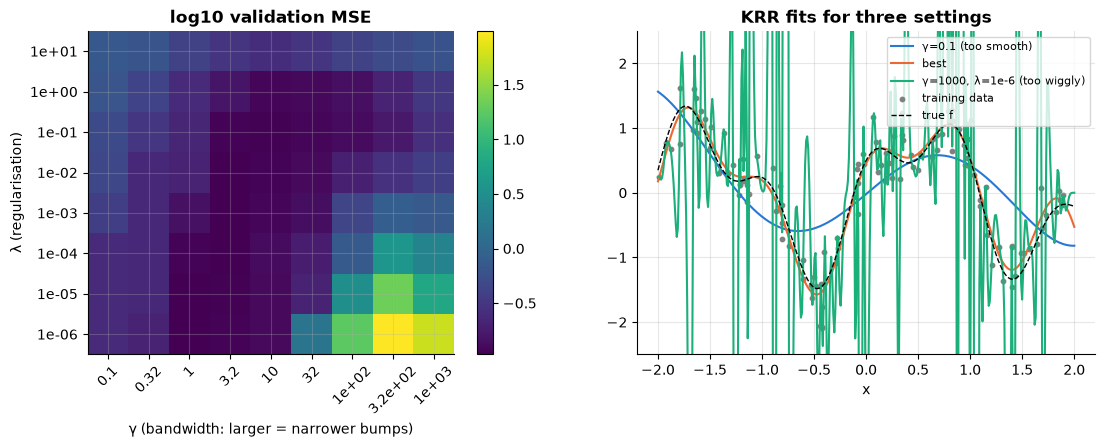

In [6]:
def krr_fit(X, y, gamma, lam):
    K = rbf_kernel(X, X, gamma)
    L = np.linalg.cholesky(K + lam * np.eye(len(X)))           # K + lam I is positive definite
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y))        # two triangular solves
    return alpha

def krr_predict(Xnew, X, alpha, gamma):
    return rbf_kernel(Xnew, X, gamma) @ alpha

r3 = np.random.default_rng(3)
f3 = lambda x: np.sin(3 * x) + 0.5 * np.cos(7 * x)
X3 = r3.uniform(-2, 2, size=(120, 1)); y3 = f3(X3[:, 0]) + 0.3 * r3.normal(size=120)
Xv = r3.uniform(-2, 2, size=(400, 1)); yv = f3(Xv[:, 0]) + 0.3 * r3.normal(size=400)

alpha3 = krr_fit(X3, y3, gamma=2.0, lam=0.1)
ours = krr_predict(Xv, X3, alpha3, 2.0)
sk = KernelRidge(alpha=0.1, kernel="rbf", gamma=2.0).fit(X3, y3).predict(Xv)
print(f"max |ours - sklearn KernelRidge| = {np.abs(ours - sk).max():.2e}")
assert np.allclose(ours, sk, atol=1e-8)

gammas = np.logspace(-1, 3, 9); lams = np.logspace(-6, 1, 8)
grid = np.array([[np.mean((krr_predict(Xv, X3, krr_fit(X3, y3, g, l), g) - yv) ** 2) for g in gammas] for l in lams])
i, j = np.unravel_index(grid.argmin(), grid.shape)
print(f"best validation MSE {grid[i, j]:.4f} at gamma = {gammas[j]:.3g}, lambda = {lams[i]:.0e}  (noise variance = 0.09)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
im = axes[0].imshow(np.log10(grid), origin="lower", cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(gammas)), [f"{g:.2g}" for g in gammas], rotation=45)
axes[0].set_yticks(range(len(lams)), [f"{l:.0e}" for l in lams])
axes[0].set_xlabel("γ (bandwidth: larger = narrower bumps)"); axes[0].set_ylabel("λ (regularisation)")
axes[0].set_title("log10 validation MSE"); plt.colorbar(im, ax=axes[0])
xs_plot = np.linspace(-2, 2, 400)[:, None]
for g, l, lab in [(0.1, 1e-3, "γ=0.1 (too smooth)"), (gammas[j], lams[i], "best"), (1000, 1e-6, "γ=1000, λ=1e-6 (too wiggly)")]:
    axes[1].plot(xs_plot, krr_predict(xs_plot, X3, krr_fit(X3, y3, g, l), g), label=lab, lw=1.5)
axes[1].scatter(X3, y3, s=10, color="gray", label="training data")
axes[1].plot(xs_plot, f3(xs_plot[:, 0]), "k--", lw=1, label="true f")
axes[1].set_ylim(-2.5, 2.5); axes[1].set_xlabel("x"); axes[1].set_title("KRR fits for three settings"); axes[1].legend(fontsize=8)
plt.show()

**What just happened?** Our 5-line KRR matches scikit-learn's `KernelRidge` to machine precision. The validation heatmap shows the **joint** effect of the two hyper-parameters. Very small $\gamma$ (wide bumps) underfits whatever $\lambda$ is. Very large $\gamma$ with tiny $\lambda$ interpolates the noise. The good region is a diagonal band: wider kernels need less regularisation and narrower kernels need more. The best validation MSE printed above sits just above the noise variance 0.09, the lowest error any model can achieve on noisy labels.

🎓 **Exam / interview tip:** "What is the difference between kernel ridge regression and an SVM regressor?" Same function class and same kind of regulariser, but a different loss. KRR uses squared loss, so it has a closed-form solution and **every** $\alpha_i$ is non-zero (no sparsity). SVR uses the $\varepsilon$-insensitive loss, which needs a QP solver but gives sparse support vectors.

## 4. Kernel PCA and kernel k-means

PCA and k-means only use dot products and distances, so swapping in a kernel lets them find curved structure.

**Kernel PCA** (Schölkopf, Smola & Müller, 1998) runs PCA in feature space:
1. **Centre the Gram matrix**: $\tilde K = HKH$ with $H = I - \frac1n\mathbf 1\mathbf 1^\top$ (this subtracts the feature-space mean).
2. Eigen-decompose $\tilde K = U\Lambda U^\top$.
3. The projection of training point $i$ on component $k$ is $\sqrt{\lambda_k}\,U_{ik}$.

**Kernel k-means** runs k-means in feature space. The squared distance from $\phi(x_i)$ to the mean of cluster $C$ needs only kernel values:

$$\lVert\phi(x_i) - \mu_C\rVert^2 = K_{ii} - \frac{2}{|C|}\sum_{j \in C}K_{ij} + \frac{1}{|C|^2}\sum_{j, l \in C}K_{jl}.$$

We use two concentric circles, where linear PCA and ordinary k-means fail by construction. This deepens [`02_dimensionality_reduction`](../02_unsupervised/02_dimensionality_reduction.ipynb) and [`01_clustering`](../02_unsupervised/01_clustering.ipynb).

max |kernel PCA ours - sklearn| (after sign alignment) = 3.79e-15
adjusted Rand index vs true rings: kernel k-means = 1.000, ordinary k-means = -0.003


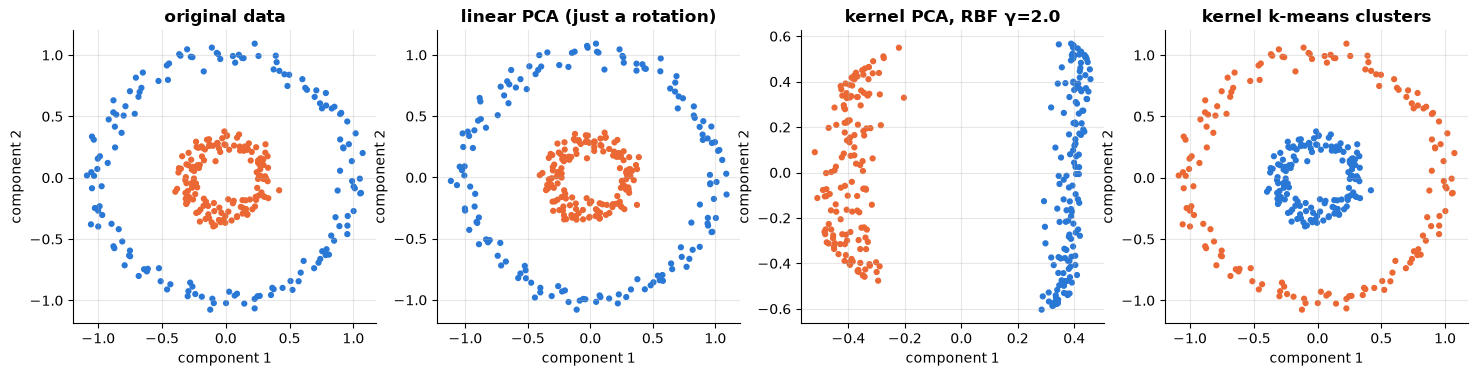

In [7]:
Xc, yc = make_circles(n_samples=300, factor=0.3, noise=0.05, random_state=0)

def kernel_pca(K, n_components):
    n = len(K)
    H = np.eye(n) - np.ones((n, n)) / n
    Kc = H @ K @ H                                             # centre in feature space
    vals, vecs = np.linalg.eigh(Kc)
    idx = np.argsort(vals)[::-1][:n_components]                # largest eigenvalues first
    return vecs[:, idx] * np.sqrt(np.maximum(vals[idx], 0))

def kernel_kmeans(K, k, restarts=10, iters=100, seed=0):
    r = np.random.default_rng(seed); n = len(K); best = (np.inf, None)
    for _ in range(restarts):
        lab = r.integers(k, size=n)
        for _ in range(iters):
            D = np.full((n, k), np.inf)
            for c in range(k):
                m = lab == c
                if m.any():
                    D[:, c] = np.diag(K) - 2 * K[:, m].mean(1) + K[np.ix_(m, m)].mean()
            new = D.argmin(1)
            if (new == lab).all():
                break
            lab = new
        obj = D[np.arange(n), lab].sum()                           # within-cluster sum of squares
        if obj < best[0]:
            best = (obj, lab)
    return best[1]

GAMMA_C = 2.0
Kc_ = rbf_kernel(Xc, Xc, GAMMA_C)
Z_ours = kernel_pca(Kc_, 2)
Z_sk = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA_C).fit_transform(Xc)
sign = np.sign((Z_ours * Z_sk).sum(0))                             # eigenvectors are defined up to sign
print(f"max |kernel PCA ours - sklearn| (after sign alignment) = {np.abs(Z_ours * sign - Z_sk).max():.2e}")
lab_kk = kernel_kmeans(Kc_, 2)
lab_km = KMeans(2, n_init=10, random_state=0).fit_predict(Xc)
print(f"adjusted Rand index vs true rings: kernel k-means = {adjusted_rand_score(yc, lab_kk):.3f}, "
      f"ordinary k-means = {adjusted_rand_score(yc, lab_km):.3f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
Z_lin = PCA(2).fit_transform(Xc)
for ax, Z, title, lab in [(axes[0], Xc, "original data", yc), (axes[1], Z_lin, "linear PCA (just a rotation)", yc),
                          (axes[2], Z_ours, f"kernel PCA, RBF γ={GAMMA_C}", yc), (axes[3], Xc, "kernel k-means clusters", lab_kk)]:
    ax.scatter(Z[:, 0], Z[:, 1], c=[PALETTE[int(l)] for l in lab], s=12)
    ax.set_title(title); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
plt.show()

**What just happened?** Linear PCA only rotates the rings, so they still overlap in every direction. Kernel PCA with an RBF kernel maps them so that the first component alone separates inner from outer ring. Our implementation matches scikit-learn's `KernelPCA` once the arbitrary sign of each eigenvector is aligned. Kernel k-means recovers the two rings perfectly (adjusted Rand index 1.0), while ordinary k-means cuts the plane in half and scores about 0.

**Complexity:** both cost $O(n^2)$ memory for the Gram matrix. Kernel PCA needs an $O(n^3)$ eigendecomposition (or $O(n^2 k)$ for the top $k$ components with iterative solvers). Kernel k-means costs $O(n^2)$ per iteration. Kernel k-means is closely related to **spectral clustering**: both optimise a normalised-cut-like objective on a similarity graph (Dhillon, Guan & Kulis, 2004).

## 5. Scaling up: Nyström and random Fourier features

Exact kernel methods need an $n \times n$ matrix, which is impossible for millions of points, so we replace the kernel by a cheap low-rank approximation.

With $n = 10^6$, the Gram matrix has $10^{12}$ entries (8 TB) and an $O(n^3)$ solve is out of the question. Both fixes below build an explicit **$D$-dimensional feature map** $z(x)$ with $z(x)^\top z(x') \approx k(x, x')$. After that, ordinary *linear* methods apply, at cost $O(nD^2)$.

**Nyström method** (Williams & Seeger, 2001). Pick $D$ landmark points (here: random training points).
- Let $C = K(X, \text{landmarks})$ ($n \times D$) and $W = K(\text{landmarks}, \text{landmarks})$.
- Then $K \approx C W^{+} C^\top$, with features $z(x) = W^{-1/2} k(\text{landmarks}, x)$.
- It is **data-dependent**: excellent when the kernel's eigenvalues decay fast.

**Random Fourier features** (Rahimi & Recht, 2007). By Bochner's theorem, a shift-invariant kernel is the Fourier transform of a probability distribution. For the RBF kernel $e^{-\gamma\lVert x - z\rVert^2}$:
- draw $w_j \sim \mathcal N(0, 2\gamma I)$ and $b_j \sim U(0, 2\pi)$;
- set $z(x) = \sqrt{2/D}\,[\cos(w_j^\top x + b_j)]_{j=1}^D$.
- The approximation is unbiased, with error $O(1/\sqrt D)$; it is **data-independent**.

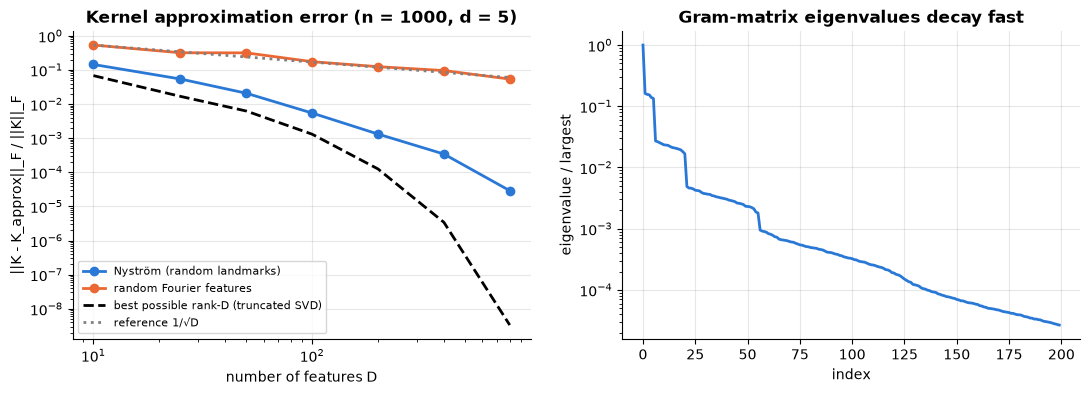

  D  Nyström error  RFF error  best rank-D
 10         0.1445     0.5363       0.0682
 25         0.0542     0.3185       0.0168
 50         0.0207     0.3167       0.0062
100         0.0054     0.1745       0.0013
200         0.0013     0.1246       0.0001
400         0.0003     0.0958       0.0000
800         0.0000     0.0540       0.0000


In [8]:
def nystrom_features(X, landmarks, gamma):
    W = rbf_kernel(landmarks, landmarks, gamma)
    vals, vecs = np.linalg.eigh(W)
    keep = vals > 1e-10 * vals.max()                               # drop numerically-zero directions
    W_inv_sqrt = vecs[:, keep] / np.sqrt(vals[keep])               # W^{-1/2} restricted to its range
    return rbf_kernel(X, landmarks, gamma) @ W_inv_sqrt

def rff_features(X, D, gamma, seed=0):
    r = np.random.default_rng(seed)
    Wf = r.normal(scale=np.sqrt(2 * gamma), size=(X.shape[1], D))
    b = r.uniform(0, 2 * np.pi, size=D)
    return np.sqrt(2.0 / D) * np.cos(X @ Wf + b)

r5 = np.random.default_rng(5)
X5 = r5.normal(size=(1000, 5)); G5 = 0.1
K5 = rbf_kernel(X5, X5, G5); normK = np.linalg.norm(K5)
Ds = [10, 25, 50, 100, 200, 400, 800]
err_ny, err_rff = [], []
for D in Ds:
    Zn = nystrom_features(X5, X5[r5.choice(1000, D, replace=False)], G5)
    Zr = rff_features(X5, D, G5, seed=D)
    err_ny.append(np.linalg.norm(K5 - Zn @ Zn.T) / normK)
    err_rff.append(np.linalg.norm(K5 - Zr @ Zr.T) / normK)
eig5 = np.sort(np.linalg.eigvalsh(K5))[::-1]
best_rank = [np.sqrt((eig5[D:] ** 2).sum()) / normK for D in Ds]  # optimal rank-D error (Eckart-Young)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(Ds, err_ny, "o-", label="Nyström (random landmarks)")
axes[0].loglog(Ds, err_rff, "o-", label="random Fourier features")
axes[0].loglog(Ds, np.maximum(best_rank, 1e-16), "k--", label="best possible rank-D (truncated SVD)")
axes[0].loglog(Ds, err_rff[0] * np.sqrt(Ds[0] / np.array(Ds)), ":", color="gray", label="reference 1/√D")
axes[0].set_xlabel("number of features D"); axes[0].set_ylabel("||K - K_approx||_F / ||K||_F")
axes[0].set_title("Kernel approximation error (n = 1000, d = 5)"); axes[0].legend(fontsize=8)
axes[1].semilogy(eig5[:200] / eig5[0])
axes[1].set_xlabel("index"); axes[1].set_ylabel("eigenvalue / largest"); axes[1].set_title("Gram-matrix eigenvalues decay fast")
plt.show()
print(pd.DataFrame({"D": Ds, "Nyström error": err_ny, "RFF error": err_rff, "best rank-D": best_rank}).round(4).to_string(index=False))

In [9]:
# Timing: exact KRR vs ridge regression on Nyström / RFF features, n = 3000 training points
r6 = np.random.default_rng(6)
f6 = lambda X: np.sin(X[:, 0]) * np.cos(X[:, 1]) + 0.5 * X[:, 2]
Xtr6 = r6.normal(size=(3000, 5)); ytr6 = f6(Xtr6) + 0.1 * r6.normal(size=3000)
Xte6 = r6.normal(size=(2000, 5)); yte6 = f6(Xte6)
G6, LAM6 = 0.1, 1e-2

def ridge_on_features(Z, y, lam):
    return np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ y)

rows = []
t0 = time.perf_counter(); a6 = krr_fit(Xtr6, ytr6, G6, LAM6); p6 = krr_predict(Xte6, Xtr6, a6, G6)
rows.append({"method": "exact KRR (n = 3000)", "features": 3000, "seconds": time.perf_counter() - t0, "test MSE": np.mean((p6 - yte6) ** 2)})
for D in [100, 300]:
    t0 = time.perf_counter()
    lm = Xtr6[r6.choice(3000, D, replace=False)]
    w = ridge_on_features(nystrom_features(Xtr6, lm, G6), ytr6, LAM6)
    p = nystrom_features(Xte6, lm, G6) @ w
    rows.append({"method": f"Nyström + ridge", "features": D, "seconds": time.perf_counter() - t0, "test MSE": np.mean((p - yte6) ** 2)})
    t0 = time.perf_counter()
    w = ridge_on_features(rff_features(Xtr6, D, G6, seed=1), ytr6, LAM6)
    p = rff_features(Xte6, D, G6, seed=1) @ w
    rows.append({"method": f"RFF + ridge", "features": D, "seconds": time.perf_counter() - t0, "test MSE": np.mean((p - yte6) ** 2)})
pd.DataFrame(rows).round(4)

,method,features,seconds,test MSE
0,exact KRR (n = 3000),3000,2.9631,0.0013
1,Nyström + ridge,100,0.1866,0.0088
2,RFF + ridge,100,0.2093,0.0123
3,Nyström + ridge,300,2.2540,0.0015
4,RFF + ridge,300,0.5639,0.0077


**What just happened?**
- **Approximation error:** Nyström tracks the best possible rank-$D$ approximation closely, because the eigenvalues of this RBF Gram matrix decay quickly (right panel) and Nyström adapts to the data. RFF error falls roughly like the $1/\sqrt D$ Monte-Carlo rate: slower, but it needs no data to build the features, which matters for streaming data or when the features must be fixed in advance.
- **Timing table:** the approximations train faster than exact KRR even at $n = 3{,}000$, and with 300 landmarks Nyström reaches nearly the same test error as exact KRR. RFF needs more features for the same accuracy, matching the left panel. (Absolute times depend on your machine.) The gap widens quickly with $n$: exact KRR is $O(n^3)$, while the approximations are $O(nD^2)$, linear in $n$.

| Method | Training cost | Memory | Best when |
|---|---|---|---|
| exact kernel | $O(n^3)$ | $O(n^2)$ | $n \lesssim 10^4$ |
| Nyström, $D$ landmarks | $O(nD^2 + D^3)$ | $O(nD)$ | fast eigen-decay, data available |
| random Fourier features | $O(nD^2)$ (+ $O(ndD)$ to build) | $O(nD)$ | shift-invariant kernels, streaming, fixed features |

## 6. The kernel two-sample test (MMD) for drift detection

MMD asks "do these two piles of data come from the same distribution?" by comparing their average positions in kernel feature space.

The **maximum mean discrepancy** between distributions $P$ and $Q$ is the distance between their mean embeddings in the RKHS:

$$\mathrm{MMD}^2(P, Q) = \lVert \mu_P - \mu_Q\rVert^2_{\mathcal H} = \mathbb E[k(x, x')] + \mathbb E[k(y, y')] - 2\,\mathbb E[k(x, y)].$$

For a **characteristic** kernel such as the RBF, $\mathrm{MMD} = 0$ if and only if $P = Q$, so it detects *any* difference: mean, variance, shape or correlation. The unbiased estimator (Gretton et al., 2012) from samples $x_{1..m}$, $y_{1..n}$ is

$$\widehat{\mathrm{MMD}}^2_u = \frac{1}{m(m-1)}\sum_{i \ne j}k(x_i, x_j) + \frac{1}{n(n-1)}\sum_{i \ne j}k(y_i, y_j) - \frac{2}{mn}\sum_{i,j}k(x_i, y_j).$$

A **permutation test** gives a p-value: shuffle the pooled sample many times, recompute the statistic, and count how often it exceeds the observed one. The bandwidth is set by the **median heuristic** ($1/\gamma$ = the median squared pairwise distance).

**Use case: data-drift monitoring** ([`15_MLOps/06_monitoring`](../../15_MLOps/06_monitoring/01_monitoring.ipynb)). Compare a reference window of production features with a new window. We contrast MMD with the common practice of running a t-test per feature.

In [10]:
def mmd2_unbiased(K, m):
    """K is the Gram matrix of the pooled sample (first m rows = sample X, rest = sample Y)."""
    n = len(K) - m
    Kxx, Kyy, Kxy = K[:m, :m], K[m:, m:], K[:m, m:]
    return ((Kxx.sum() - np.trace(Kxx)) / (m * (m - 1)) + (Kyy.sum() - np.trace(Kyy)) / (n * (n - 1))
            - 2 * Kxy.mean())

def mmd_permutation_test(X, Y, n_perm=500, seed=0):
    Z = np.vstack([X, Y]); m = len(X)
    D2 = sqdist(Z, Z)
    gamma = 1.0 / np.median(D2[np.triu_indices(len(Z), 1)])        # median heuristic
    K = np.exp(-gamma * D2)
    observed = mmd2_unbiased(K, m)
    r = np.random.default_rng(seed); count = 0
    for _ in range(n_perm):
        p = r.permutation(len(Z))
        count += mmd2_unbiased(K[np.ix_(p, p)], m) >= observed
    return observed, (count + 1) / (n_perm + 1)

r7 = np.random.default_rng(7)
ref = r7.normal(size=(200, 5))
scenarios = {
    "no drift (same distribution)": r7.normal(size=(200, 5)),
    "mean shift +0.4 in feature 0": r7.normal(size=(200, 5)) + np.array([0.4, 0, 0, 0, 0]),
    "variance x1.8 in feature 1 (same mean)": r7.normal(size=(200, 5)) * np.array([1, 1.8, 1, 1, 1]),
    "correlation appears (same marginals)": None,
}
Zc = r7.normal(size=(200, 5)); Zc[:, 3] = 0.8 * Zc[:, 2] + 0.6 * Zc[:, 3]      # corr(f2, f3) = 0.8, each still N(0,1)
scenarios["correlation appears (same marginals)"] = Zc
rows = []
for name, new in scenarios.items():
    stat, p = mmd_permutation_test(ref, new)
    t_p = min(stats.ttest_ind(ref[:, j], new[:, j]).pvalue for j in range(5)) * 5      # Bonferroni over 5 features
    rows.append({"scenario": name, "MMD² (unbiased)": stat, "MMD p-value": p, "per-feature t-test p (Bonferroni)": min(t_p, 1.0)})
drift = pd.DataFrame(rows)
drift.round(4)

,scenario,MMD² (unbiased),MMD p-value,per-feature t-test p (Bonferroni)
0,no drift (same distribution),0.0013,0.2076,1.000
1,mean shift +0.4 in feature 0,0.0215,0.0020,0.000
2,variance x1.8 in feature 1 (same mean),0.0225,0.0020,0.137
3,correlation appears (same marginals),0.0090,0.0020,1.000


**What just happened?** With no drift, MMD² is close to zero and its p-value is large (no alarm). Both MMD and the per-feature t-tests catch the **mean shift**. Only MMD catches the **variance change** and the **new correlation** between features 2 and 3: every feature still has mean 0, so a t-test, which only compares means, has nothing to see. Univariate tests also miss correlation changes entirely, even variance-sensitive ones such as Kolmogorov–Smirnov, because each feature's marginal distribution is unchanged.

**Complexity:** $O((m+n)^2 d)$ for the Gram matrix, and the same per permutation (re-indexing the matrix). For large windows, linear-time MMD estimators and random-feature versions exist.

⚠️ **Common mistake:** choosing the bandwidth on the same data you test, by maximising the statistic, then reporting the permutation p-value. That invalidates the test. Either use a fixed rule (median heuristic) or select the bandwidth on a separate split.

## 7. The kernel–Gaussian-process connection

A Gaussian process with a kernel as its covariance makes exactly the same mean prediction as kernel ridge regression, and adds error bars.

A **Gaussian process** $f \sim \mathcal{GP}(0, k)$ is a prior over functions in which any finite set of values $(f(x_1), \dots, f(x_n))$ is jointly Gaussian with covariance $K$. With observations $y = f(X) + \varepsilon$, $\varepsilon \sim \mathcal N(0, \sigma^2 I)$, the posterior at a new point $x_*$ is Gaussian with

$$\mu(x_*) = k(x_*, X)\,(K + \sigma^2 I)^{-1}y, \qquad \operatorname{Var}(x_*) = k(x_*, x_*) - k(x_*, X)(K + \sigma^2 I)^{-1}k(X, x_*).$$

The **posterior mean is exactly the KRR predictor with $\lambda = \sigma^2$**. KRR is the "frequentist" view (a penalised fit in the RKHS); the GP is the Bayesian view, and it also returns uncertainty. One subtlety: samples from the GP are almost surely *not* in the RKHS of $k$ (they are rougher), even though the posterior mean is.

scikit-learn's `RBF(length_scale=ℓ)` is $\exp(-\lVert x - z\rVert^2 / (2\ell^2))$, i.e. $\gamma = 1/(2\ell^2)$.

max |KRR prediction - GP posterior mean| = 1.27e-14
max |our posterior std - sklearn std|    = 6.66e-15


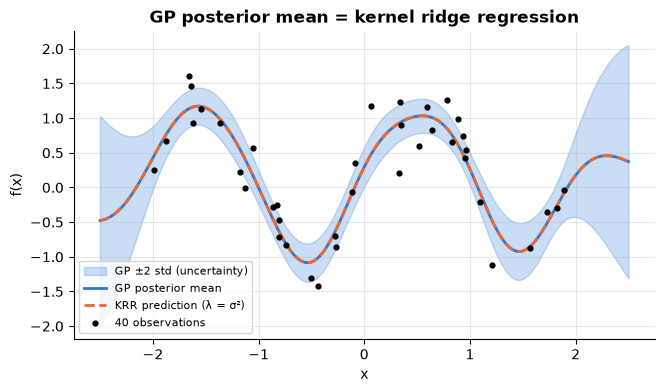

In [11]:
ell, noise_var = 0.5, 0.09
gamma_gp = 1 / (2 * ell**2)
X7 = X3[:40]; y7 = y3[:40]                                          # reuse 40 points from Section 3
xs7 = np.linspace(-2.5, 2.5, 300)[:, None]
mu_krr = krr_predict(xs7, X7, krr_fit(X7, y7, gamma_gp, noise_var), gamma_gp)

gpr = GaussianProcessRegressor(kernel=RBF(length_scale=ell, length_scale_bounds="fixed"),
                               alpha=noise_var, optimizer=None).fit(X7, y7)
mu_gp, sd_gp = gpr.predict(xs7, return_std=True)

# from-scratch posterior variance
Kxx = rbf_kernel(X7, X7, gamma_gp) + noise_var * np.eye(len(X7))
Ksx = rbf_kernel(xs7, X7, gamma_gp)
var_ours = 1.0 - np.einsum("ij,ji->i", Ksx, np.linalg.solve(Kxx, Ksx.T))
print(f"max |KRR prediction - GP posterior mean| = {np.abs(mu_krr - mu_gp).max():.2e}")
print(f"max |our posterior std - sklearn std|    = {np.abs(np.sqrt(np.maximum(var_ours, 0)) - sd_gp).max():.2e}")
assert np.allclose(mu_krr, mu_gp, atol=1e-8)

plt.figure(figsize=(7.5, 4))
plt.fill_between(xs7[:, 0], mu_gp - 2 * sd_gp, mu_gp + 2 * sd_gp, alpha=0.25, color=PALETTE[0], label="GP ±2 std (uncertainty)")
plt.plot(xs7, mu_gp, color=PALETTE[0], label="GP posterior mean")
plt.plot(xs7, mu_krr, "--", color=PALETTE[1], label="KRR prediction (λ = σ²)")
plt.scatter(X7, y7, color="black", s=12, zorder=3, label="40 observations")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("GP posterior mean = kernel ridge regression"); plt.legend(fontsize=8)
plt.show()

**What just happened?** The KRR predictor and the GP posterior mean coincide to machine precision, and our from-scratch posterior standard deviation matches scikit-learn's. The uncertainty band is narrow near the data and widens in the gaps and beyond $|x| > 2$, where there are no observations. This is the extra information the Bayesian view gives for free, and why GPs drive Bayesian optimisation ([`02_industry_gaussian_process_process_optimization`](../04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb)).

## 8. Kernels for structured data: strings and graphs

Kernels let us compare things that are not vectors, such as DNA sequences or molecules, by counting shared building blocks.

**Spectrum kernel for strings** (Leslie, Eskin & Noble, 2002). Let $\phi_k(s)$ be the vector of counts of every length-$k$ substring ($k$-mer) of $s$. Then $k(s, t) = \langle\phi_k(s), \phi_k(t)\rangle$. It is a valid kernel by construction (an explicit feature map) and is computed with hash maps without enumerating all $4^k$ possible $k$-mers. Used for protein and DNA classification, and as a forerunner of $n$-gram text features.

**Weisfeiler–Lehman (WL) subtree kernel for graphs** (Shervashidze et al., 2011). Start with node labels (here: degrees). In each iteration, relabel every node by the pair (its label, the sorted multiset of its neighbours' labels), compressed to a new label. The feature vector of a graph counts how often each label occurs across iterations, and the kernel is the dot product. The relabelling is exactly the message passing of a graph neural network ([`05_Deep_Learning/07_gnn`](../../05_Deep_Learning/07_gnn.ipynb)); a standard GNN can be at most as powerful as the WL test at telling graphs apart (Xu et al., 2019).

In [12]:
# --- strings: class 1 sequences contain the motif GATTACA somewhere; class 0 are random
r8 = np.random.default_rng(8)
ALPH = np.array(list("ACGT"))
def random_seq(L):
    return "".join(r8.choice(ALPH, L))
def with_motif(L, motif="GATTACA"):
    s = list(random_seq(L)); pos = r8.integers(0, L - len(motif))
    s[pos:pos + len(motif)] = list(motif)                        # plant the motif at a random position
    return "".join(s)
seqs = [random_seq(40) for _ in range(60)] + [with_motif(40) for _ in range(60)]
labels_s = np.array([0] * 60 + [1] * 60)

def spectrum_features(seqs, k):
    counts = [Counter(s[i:i + k] for i in range(len(s) - k + 1)) for s in seqs]
    vocab = sorted(set().union(*counts))
    F = np.array([[c[w] for w in vocab] for c in counts], dtype=float)
    return F / np.linalg.norm(F, axis=1, keepdims=True)           # normalise: k(s,s) = 1

cv = StratifiedKFold(5, shuffle=True, random_state=0)
for k in [1, 2, 3, 4, 5, 6]:
    F = spectrum_features(seqs, k)
    Kspec = F @ F.T
    acc = cross_val_score(SVC(kernel="precomputed", C=10), Kspec, labels_s, cv=cv).mean()
    print(f"spectrum kernel k = {k}: {F.shape[1]:4d} distinct k-mers, min Gram eigenvalue = {np.linalg.eigvalsh(Kspec).min():+.1e}, "
          f"5-fold CV accuracy = {acc:.3f}")

spectrum kernel k = 1:    4 distinct k-mers, min Gram eigenvalue = -3.9e-14, 5-fold CV accuracy = 0.633
spectrum kernel k = 2:   16 distinct k-mers, min Gram eigenvalue = -2.6e-14, 5-fold CV accuracy = 0.650
spectrum kernel k = 3:   64 distinct k-mers, min Gram eigenvalue = -4.8e-15, 5-fold CV accuracy = 0.817
spectrum kernel k = 4:  256 distinct k-mers, min Gram eigenvalue = +4.6e-02, 5-fold CV accuracy = 0.950


spectrum kernel k = 5: 1003 distinct k-mers, min Gram eigenvalue = +3.2e-01, 5-fold CV accuracy = 1.000
spectrum kernel k = 6: 2550 distinct k-mers, min Gram eigenvalue = +5.5e-01, 5-fold CV accuracy = 1.000


In [13]:
# --- graphs: "friend groups" (relaxed caveman: 5 groups of 6, a few edges rewired) vs the SAME graphs
#     after a degree-preserving random shuffle of their edges. Both classes have identical degree sequences.
def wl_features(graphs, iterations):
    """Weisfeiler-Lehman subtree features: label counts over iterations 0..h (initial label = degree)."""
    labels = [{v: str(G.degree(v)) for v in G} for G in graphs]
    feats = [Counter(l.values()) for l in labels]
    for it in range(iterations):
        new_labels = []
        for G, lab in zip(graphs, labels):
            nl = {v: f"{it}|{lab[v]}|" + ",".join(sorted(lab[u] for u in G[v])) for v in G}
            new_labels.append(nl)
        labels = new_labels
        for f, l in zip(feats, labels):
            f.update(l.values())
    vocab = sorted(set().union(*feats))
    return np.array([[f[w] for w in vocab] for f in feats], dtype=float)

graphs, gl = [], []
for i in range(50):
    cave = nx.relaxed_caveman_graph(5, 6, 0.1, seed=i)
    shuffled = cave.copy()
    nx.double_edge_swap(shuffled, nswap=3 * cave.number_of_edges(), max_tries=100_000, seed=100 + i)
    assert sorted(d for _, d in cave.degree()) == sorted(d for _, d in shuffled.degree())
    graphs += [shuffled, cave]; gl += [0, 1]
gl = np.array(gl)
for h in [0, 1, 2, 3]:
    F = wl_features(graphs, h)
    Kwl = F @ F.T
    Kn = Kwl / np.sqrt(np.outer(np.diag(Kwl), np.diag(Kwl)))      # cosine-normalised kernel
    acc = cross_val_score(SVC(kernel="precomputed", C=1), Kn, gl, cv=cv).mean()
    print(f"WL iterations h = {h}: {F.shape[1]:5d} features, 5-fold CV accuracy = {acc:.3f}")

# WL features are invariant to renaming the nodes (a property any graph kernel must have)
G0 = graphs[1]
G0_perm = nx.relabel_nodes(G0, dict(zip(G0.nodes, r8.permutation(len(G0)))))
Fa, Fb = wl_features([G0, G0_perm], 3)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                               # networkx notes a hash-format change in v3.5
    same_hash = nx.weisfeiler_lehman_graph_hash(G0) == nx.weisfeiler_lehman_graph_hash(G0_perm)
print("identical WL features after relabelling nodes:", np.array_equal(Fa, Fb), "| networkx WL hash equal:", same_hash)

WL iterations h = 0:     7 features, 5-fold CV accuracy = 0.370
WL iterations h = 1:   198 features, 5-fold CV accuracy = 0.410


WL iterations h = 2:  2246 features, 5-fold CV accuracy = 0.720


WL iterations h = 3:  4634 features, 5-fold CV accuracy = 0.710
identical WL features after relabelling nodes: True | networkx WL hash equal: True


**What just happened?**
- **Strings:** with $k = 1$ (letter counts only) accuracy is only a little above chance: inserting a 7-letter motif into 40 letters barely changes letter frequencies. As $k$ grows, the $k$-mers capture pieces of GATTACA itself, and accuracy climbs to 100% by $k = 5$. Every spectrum Gram matrix is PSD, as it must be for an explicit feature map (the tiny negative values are rounding).
- **Graphs:** each "friend-group" graph is paired with a copy whose edges were randomly re-wired **keeping every node's degree**. At $h = 0$ (degree counts only) the two classes are indistinguishable and accuracy is at chance level, as it must be. Each WL iteration looks one step further into the neighbourhood. One step (your friends' degrees) barely helps; from $h = 2$ on (friends of friends, i.e. whether your friends know each other) accuracy rises to about 0.7. The features are unchanged when nodes are renamed, a property shared with networkx's WL hash.
- 1-WL has known blind spots: it cannot tell apart two regular graphs with the same degree, and it cannot count triangles in general. That is why accuracy here stays below 100%, and why more expressive "higher-order" GNNs exist.

## 9. The neural tangent kernel

A very wide neural network, trained by plain gradient descent, barely moves its weights, so it behaves like a fixed kernel method.

For a network $f(x; \theta)$, the **neural tangent kernel** (NTK; Jacot, Gabriel & Hongler, 2018) is

$$\Theta(x, x') = \nabla_\theta f(x; \theta)^\top \nabla_\theta f(x'; \theta).$$

Under gradient descent on the squared loss, the network outputs on the training set evolve as $\dot f = -\Theta\,(f - y)$. In the **infinite-width limit** (with the "NTK parameterisation" $f = \frac{1}{\sqrt m}\sum_j a_j\,\mathrm{relu}(w_j^\top x)$), three things happen:
1. the weights move only $O(1/\sqrt m)$ relative to their size;
2. $\Theta$ stays essentially constant during training;
3. the trained network equals **kernel regression with $\Theta$**, started from the initial function.

For discrete gradient descent with step $\eta$ for $T$ steps, the *linearised* model predicts

$$f_T(x) = f_0(x) - \Theta(x, X)\,\Theta(X, X)^{-1}\big(I - (I - \eta\Theta(X, X))^T\big)\big(f_0(X) - y\big).$$

We train real two-layer ReLU networks of increasing width with full-batch gradient descent (gradients written by hand in numpy) and compare them with this kernel prediction, computed from the **empirical NTK at initialisation**.

(all four widths trained in 3.1 s)
 width  relative weight change  relative NTK change  RMS(network - kernel prediction)  train max error
    10                  1.6087               1.5954                            0.2342           0.0958
   100                  0.3842               0.2463                            0.1629           0.0508
  1000                  0.1140               0.0531                            0.0671           0.0024
 10000                  0.0339               0.0124                            0.0312           0.0003


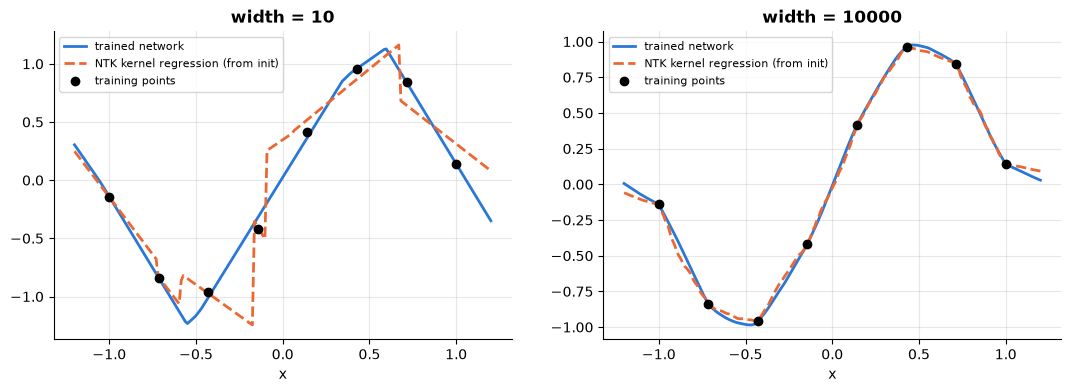

In [14]:
def ntk_experiment(width, steps=3000, seed=0):
    r = np.random.default_rng(seed)
    Xn = np.linspace(-1, 1, 8); yn = np.sin(3 * Xn)                      # 8 training points
    Xq = np.linspace(-1.2, 1.2, 200)                                     # query points
    aug = lambda x: np.stack([x, np.ones_like(x)], 1)                    # input plus a bias feature
    W = r.normal(size=(width, 2)); a = r.normal(size=width)              # NTK parameterisation
    net = lambda W, a, x: np.maximum(aug(x) @ W.T, 0) @ a / np.sqrt(width)

    def ntk(W, a, x1, x2):
        A1, A2 = aug(x1), aug(x2); h1, h2 = A1 @ W.T, A2 @ W.T
        # gradient w.r.t. a_j: relu(h)/sqrt(m);  gradient w.r.t. w_j: a_j * 1[h>0] * x / sqrt(m)
        return (np.maximum(h1, 0) @ np.maximum(h2, 0).T + ((h1 > 0) * a) @ ((h2 > 0) * a).T * (A1 @ A2.T)) / width

    K = ntk(W, a, Xn, Xn); Kq = ntk(W, a, Xq, Xn)
    eta = 1.0 / np.linalg.eigvalsh(K).max()
    r0 = net(W, a, Xn) - yn
    decay = np.eye(8) - np.linalg.matrix_power(np.eye(8) - eta * K, steps)
    kernel_pred = net(W, a, Xq) - Kq @ np.linalg.solve(K, decay @ r0)   # linearised (kernel) prediction

    W0 = W.copy()
    for _ in range(steps):                                               # real gradient descent on 1/2 ||f - y||^2
        h = aug(Xn) @ W.T
        res = np.maximum(h, 0) @ a / np.sqrt(width) - yn
        grad_a = np.maximum(h, 0).T @ res / np.sqrt(width)
        grad_W = ((h > 0) * a).T @ (res[:, None] * aug(Xn)) / np.sqrt(width)
        a = a - eta * grad_a; W = W - eta * grad_W
    net_pred = net(W, a, Xq)
    K_end = ntk(W, a, Xn, Xn)
    return {"width": width,
            "relative weight change": np.linalg.norm(W - W0) / np.linalg.norm(W0),
            "relative NTK change": np.linalg.norm(K_end - K) / np.linalg.norm(K),
            "RMS(network - kernel prediction)": np.sqrt(np.mean((net_pred - kernel_pred) ** 2)),
            "train max error": np.abs(net(W, a, Xn) - yn).max()}, (Xn, yn, Xq, net_pred, kernel_pred)

results, curves = [], {}
t0 = time.time()
for wdt in [10, 100, 1000, 10000]:
    res, cur = ntk_experiment(wdt)
    results.append(res); curves[wdt] = cur
print(f"(all four widths trained in {time.time() - t0:.1f} s)")
ntk_tab = pd.DataFrame(results)
print(ntk_tab.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, wdt in zip(axes, [10, 10000]):
    Xn, yn, Xq, net_pred, kernel_pred = curves[wdt]
    ax.plot(Xq, net_pred, label="trained network")
    ax.plot(Xq, kernel_pred, "--", label="NTK kernel regression (from init)")
    ax.scatter(Xn, yn, color="black", zorder=3, label="training points")
    ax.set_title(f"width = {wdt}"); ax.set_xlabel("x"); ax.legend(fontsize=8)
plt.show()

**What just happened?**
- As the width grows from 10 to 10,000, the relative change of the hidden weights during training shrinks roughly like $1/\sqrt{\text{width}}$, and so does the change of the NTK itself.
- The distance between the trained network and the kernel prediction shrinks too. At width 10,000 the two curves in the right panel lie almost on top of each other. At width 10 (left) the network has moved far from its initialisation, and the kernel description is only rough.

This is the **"lazy training"** or kernel regime. It explains why very wide networks are easy to optimise (the problem becomes a convex kernel regression) and lets kernel theory make statements about them. It also shows the limitation: a network in the kernel regime **does not learn features**, because its kernel is frozen at initialisation. Practical networks of finite width do learn features, which is a big part of why they beat kernel methods on images and text (Chizat, Oyallon & Bach, 2019).

## 10. Summary table

> 💬 **In plain English:** one table comparing every kernel method in this notebook by cost and use.

| Method | What the kernel replaces | Training cost | Prediction cost | Notes |
|---|---|---|---|---|
| kernel ridge regression | $x^\top z$ in ridge regression | $O(n^3)$ | $O(n)$ kernel evaluations | closed form; equals the GP posterior mean |
| SVM / SVR | $x^\top z$ in the QP dual | $O(n^2)$–$O(n^3)$ (SMO) | $O(\#\text{SV})$ | sparse solution |
| Gaussian process | covariance function | $O(n^3)$ | $O(n)$ mean, $O(n^2)$ variance | gives uncertainty |
| kernel PCA | covariance → centred Gram | $O(n^3)$ (or $O(n^2k)$) | $O(n)$ per point | non-linear dimensionality reduction |
| kernel k-means | distances in feature space | $O(n^2)$ per iteration | $O(n)$ | related to spectral clustering |
| MMD test | difference of mean embeddings | $O(n^2)$ per permutation | – | detects any distribution change |
| Nyström / RFF | the Gram matrix | $O(nD^2)$ | $O(D)$ | turns kernels into linear models |
| NTK | gradient inner products | (implicit) | – | infinite-width network limit |

## 11. 🔗 How this connects to modern AI

> 💬 **In plain English:** kernels hide inside transformers' attention, retrieval, Bayesian optimisation, GNNs and the theory of wide networks.

- **Attention is a kernel smoother:** softmax attention computes $\sum_j \frac{\exp(q^\top k_j)}{\sum_l \exp(q^\top k_l)} v_j$, a normalised kernel (Nadaraya–Watson) regression with the exponential kernel. **Performer** and other linear-attention transformers replace it with **random features** (Section 5) to get $O(n)$ instead of $O(n^2)$ cost in sequence length ([`05_Deep_Learning/05_transformers_architecture`](../../05_Deep_Learning/05_transformers_architecture.ipynb), [`08_LLM/13_inference_optimization`](../../08_LLM/13_inference_optimization.ipynb)).
- **Embeddings + cosine similarity** in retrieval and RAG are a learned linear kernel on top of a neural feature map ([`07_NLP/13_industry_semantic_search_engine`](../../07_NLP/13_industry_semantic_search_engine.ipynb)).
- **Bayesian optimisation** for hyper-parameter tuning uses GPs with kernels (Section 7) ([`06_model_evaluation/02_hyperparameter_optimization`](../06_model_evaluation/02_hyperparameter_optimization.ipynb)).
- **Drift detection and generative-model evaluation:** MMD is used for drift monitoring, and the **kernel inception distance (KID)** used to evaluate image generators is an MMD with a polynomial kernel on network features.
- **Graph neural networks** generalise the WL relabelling of Section 8 with learned functions ([`05_Deep_Learning/07_gnn`](../../05_Deep_Learning/07_gnn.ipynb)).
- **Theory of deep learning:** the NTK and the "lazy vs feature-learning" regimes are the main lens for analysing very wide networks, and connect to the double descent seen in [`01_statistical_learning_theory`](01_statistical_learning_theory.ipynb).

## Recap (key takeaways)

- A **kernel** is an inner product in a feature space: $k(x, z) = \langle\phi(x), \phi(z)\rangle$. It is valid **iff every Gram matrix is PSD** (Mercer), and new kernels are built with sums, products, positive scaling, $\exp$ and feature-wise reweighting.
- The **RKHS norm** measures function complexity. The **representer theorem** says regularised risk minimisers are $\sum_i\alpha_i k(x_i, \cdot)$, turning infinite-dimensional problems into $n$-dimensional ones.
- **Kernel ridge regression:** $\alpha = (K + \lambda I)^{-1}y$, with $O(n^3)$ cost. Its predictor equals the **GP posterior mean** with $\lambda = \sigma^2$.
- **Kernel PCA** centres the Gram matrix and eigen-decomposes it; **kernel k-means** computes feature-space distances from kernel values. Both separate structures that linear methods cannot.
- **Nyström** (data-dependent, follows the eigenvalue decay) and **random Fourier features** (data-independent, $O(1/\sqrt D)$ error) make kernels scale to large $n$.
- **MMD** with a characteristic kernel detects *any* distribution change, including variance and correlation changes that per-feature tests miss.
- Kernels exist for **strings** ($k$-mer spectrum) and **graphs** (Weisfeiler–Lehman).
- Very wide networks trained by gradient descent behave like **kernel regression with the NTK**. Their weights barely move, and they do not learn features.

## Practice problems

**1. (Easy, code)** Write the explicit feature map of $k(x, z) = (x^\top z)^2$ for 2-D inputs and verify it numerically.

<details><summary>Show solution</summary>

$(x^\top z)^2 = x_1^2 z_1^2 + x_2^2 z_2^2 + 2x_1x_2z_1z_2$, so $\phi(x) = (x_1^2, x_2^2, \sqrt2\,x_1x_2)$.

```python
import numpy as np
def phi(x):                      # explicit map for k(x, z) = (x.z)^2 in 2-D
    return np.array([x[0] ** 2, x[1] ** 2, np.sqrt(2) * x[0] * x[1]])
r = np.random.default_rng(0)
P, Q = r.normal(size=(500, 2)), r.normal(size=(500, 2))
ok = np.allclose([phi(p) @ phi(q) for p, q in zip(P, Q)], (P * Q).sum(1) ** 2)
print("phi(x).phi(z) == (x.z)^2 on 500 random pairs:", ok)
```

</details>

**2. (Easy, conceptual + code)** Is $k(x, z) = \lVert x - z\rVert^2$ a valid kernel? Prove your answer with one line of linear algebra, then check numerically.

<details><summary>Show solution</summary>

No. Its Gram matrix has zeros on the diagonal, so its trace, which equals the sum of its eigenvalues, is 0. Because the matrix is not the zero matrix, at least one eigenvalue must be negative, so it is not PSD.

```python
import numpy as np
r = np.random.default_rng(1)
X = r.normal(size=(20, 3))
D2 = ((X[:, None] - X[None]) ** 2).sum(-1)          # "kernel" ||x - z||^2
eig = np.linalg.eigvalsh(D2)
print("trace =", np.trace(D2), "| smallest eigenvalue =", eig.min().round(3))
```

</details>

**3. (Medium, code)** Implement kernel ridge regression with the Laplacian kernel $\exp(-\gamma\lVert x - z\rVert_1)$ and match scikit-learn's `KernelRidge(kernel="laplacian")`.

<details><summary>Show solution</summary>

```python
import numpy as np
from sklearn.kernel_ridge import KernelRidge

def laplacian_kernel(A, B, gamma):
    return np.exp(-gamma * np.abs(A[:, None, :] - B[None, :, :]).sum(-1))

r = np.random.default_rng(2)
X = r.uniform(-2, 2, size=(80, 2)); y = np.sin(X[:, 0]) + X[:, 1] ** 2 + 0.1 * r.normal(size=80)
Xt = r.uniform(-2, 2, size=(50, 2))
gamma, lam = 0.7, 0.05
alpha = np.linalg.solve(laplacian_kernel(X, X, gamma) + lam * np.eye(80), y)
ours = laplacian_kernel(Xt, X, gamma) @ alpha
sk = KernelRidge(alpha=lam, kernel="laplacian", gamma=gamma).fit(X, y).predict(Xt)
print("max |ours - sklearn| =", np.abs(ours - sk).max())
```

</details>

**4. (Hard, code)** Derive and implement random Fourier features for the Laplacian kernel. Hint: the Fourier transform of $e^{-\gamma|t|}$ is a Cauchy density.

<details><summary>Show solution</summary>

In 1-D, $e^{-\gamma|t|} = \mathbb E_{w \sim \text{Cauchy}(0, \gamma)}[\cos(wt)]$. The $\ell_1$ Laplacian kernel is a product over coordinates, so each coordinate of $w$ is drawn independently from Cauchy$(0, \gamma)$. The error shrinks like $1/\sqrt D$.

```python
import numpy as np

def laplacian_kernel(A, B, gamma):
    return np.exp(-gamma * np.abs(A[:, None, :] - B[None, :, :]).sum(-1))

def rff_laplacian(X, D, gamma, seed=0):
    """Bochner: the Fourier transform of exp(-gamma|t|) in each coordinate is a Cauchy density with scale gamma."""
    r = np.random.default_rng(seed)
    W = r.standard_cauchy(size=(X.shape[1], D)) * gamma
    b = r.uniform(0, 2 * np.pi, D)
    return np.sqrt(2 / D) * np.cos(X @ W + b)

r = np.random.default_rng(3)
X = r.normal(size=(300, 3)); K = laplacian_kernel(X, X, 0.5)
errs = {}
for D in [50, 500, 5000]:
    Z = rff_laplacian(X, D, 0.5, seed=D)
    errs[D] = np.linalg.norm(K - Z @ Z.T) / np.linalg.norm(K)
    print(f"D = {D:5d}: relative Frobenius error = {errs[D]:.4f}")
```

</details>

**5. (Medium, code + proof)** Show that the (biased) MMD² with the **linear** kernel equals $\lVert\bar x - \bar y\rVert^2$. What does this tell you about using a linear kernel for drift detection?

<details><summary>Show solution</summary>

$\frac{1}{m^2}\sum_{ij}x_i^\top x_j + \frac1{n^2}\sum_{ij}y_i^\top y_j - \frac2{mn}\sum_{ij}x_i^\top y_j = \bar x^\top\bar x + \bar y^\top \bar y - 2\bar x^\top\bar y = \lVert\bar x - \bar y\rVert^2$. A linear-kernel MMD only compares **means**, so it cannot see variance or correlation drift. You need a characteristic kernel such as the RBF.

```python
import numpy as np
r = np.random.default_rng(4)
X, Y = r.normal(size=(150, 4)), r.normal(size=(120, 4)) + 0.3
# biased (V-statistic) MMD^2 with the linear kernel k(x, z) = x.z
Kxx, Kyy, Kxy = X @ X.T, Y @ Y.T, X @ Y.T
mmd2_linear = Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()
mean_gap2 = np.sum((X.mean(0) - Y.mean(0)) ** 2)
print(f"linear-kernel MMD^2 = {mmd2_linear:.6f},  ||mean(X) - mean(Y)||^2 = {mean_gap2:.6f}")
```

</details>

**6. (Medium, conceptual)** Why does the representer theorem require the regulariser to be a *strictly increasing* function of $\lVert f\rVert_{\mathcal H}$? What goes wrong if there is no regulariser?

<details><summary>Show solution</summary>

In the proof, the component $f_\perp$ orthogonal to the span of $\{k(x_i, \cdot)\}$ does not change the loss. A strictly increasing $\Omega$ makes any non-zero $f_\perp$ strictly worse, so the minimiser has $f_\perp = 0$. With no regulariser (or a merely non-decreasing one), minimisers *still exist* in the span (you can always drop $f_\perp$ for free), but they are no longer the *only* minimisers. In addition, without regularisation KRR interpolates the noise ($\lambda = 0$ gives $\alpha = K^{-1}y$, which is ill-conditioned for RBF kernels).

</details>

**7. (Hard, conceptual)** You must fit a kernel model on $n = 2 \times 10^6$ points. Compare exact KRR, Nyström and random Fourier features on time, memory and accuracy, and say when you would prefer each approximation.

<details><summary>Show solution</summary>

Exact KRR needs a $2\cdot10^6 \times 2\cdot10^6$ Gram matrix (32 TB in float64) and an $O(n^3) \approx 10^{19}$-flop solve: impossible. With $D \approx 10^3$ features, both approximations need $O(nD) = 2\cdot10^9$ numbers (16 GB) and $O(nD^2) = 2\cdot10^{12}$ flops: feasible.
- **Nyström** adapts to the data and is more accurate for a given $D$ when the spectrum decays fast. Prefer it when the data are available up front.
- **RFF** needs no data to build its features, works for any shift-invariant kernel, and suits streaming or distributed settings where the feature map must be fixed in advance.

Both can be combined with SGD to avoid even the $D \times D$ solve.

</details>

## Further reading (additional learning resources)

- B. Schölkopf and A. Smola, *Learning with Kernels*, MIT Press, 2002. Chapters 1–4 (kernels, RKHS, representer theorem) and 14 (kernel PCA).
- C. E. Rasmussen and C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006. Chapters 2 and 6 (the RKHS link). Free online at gaussianprocess.org.
- A. Rahimi and B. Recht, "Random Features for Large-Scale Kernel Machines", NeurIPS 2007; C. Williams and M. Seeger, "Using the Nyström Method to Speed Up Kernel Machines", NeurIPS 2001.
- A. Gretton, K. Borgwardt, M. Rasch, B. Schölkopf and A. Smola, "A Kernel Two-Sample Test", *JMLR*, 2012.
- N. Shervashidze et al., "Weisfeiler–Lehman Graph Kernels", *JMLR*, 2011.
- A. Jacot, F. Gabriel and C. Hongler, "Neural Tangent Kernel: Convergence and Generalization in Neural Networks", NeurIPS 2018.
- The scikit-learn user guide sections on kernel ridge regression, kernel approximation and Gaussian processes (free online).

## Next notebook

Continue with [`03_Machine_Learning/17_probabilistic_graphical_models/01_markov_networks_and_exact_inference.ipynb`](../17_probabilistic_graphical_models/01_markov_networks_and_exact_inference.ipynb), which moves from similarity-based models to **structured probabilistic models**: Markov networks, factor graphs, variable elimination, belief propagation and CRFs.